# LLM scores vs. the earnings surprise: results and comparison with Koijen & Levy (2026)

Every in-sample Q4 2025 call was summarized and then scored by **Qwen3-30B-A3B-Instruct-2507** (Ollama,
`qwen3:30b-a3b-instruct-2507-q4_K_M`), using the prompts in `llm/llm_summarize.py` and `llm/llm_score.py`. The
scorer read the summary only (`score_source = summary`). This notebook:

1. **Merges** the LLM output into the pipeline's surprise and return data.
2. Runs the paper's **main regressions** (its Tables 2-3): `PRank(r_abn) = a + γ·ĝ + θ·PRank(s)`. Each R² comes with
   a 99% bootstrap interval (1,000 resamples, as in the paper), and the gain over the surprise (ΔR²) gets a paired
   interval.
3. **Compares** the results with the paper, model by model.
4. Splits the quarter into **early vs. late** halves (the paper's Table 5) and checks **calibration**: is the
   model biased toward "good news"?

**Data:**
- Pipeline dataset: `data/processed/earnings_calls_ibes_<period>.parquet`, built by `uv run doit`.
- LLM output: `data/processed/llm_merged_<period>.parquet`, built by the scoring run.
- Both are joined on `transcriptid`. The period follows `config.yaml`.

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display

from llm_based_earnings_surprise_ntam.pipeline.config import load_config
from llm_based_earnings_surprise_ntam.llm.llm_common import MERGED

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 120)

# Same chart style as the other notebooks; categorical colors in fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
PAPER_GREY = '#8a8984'   # the paper's numbers: a neutral reference, not a series hue
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

CFG = load_config()
LLM_FILE = MERGED.parent / f"llm_merged_{CFG['tag']}.parquet"
LLM_COLS = ['summary', 'sum_words_in', 'sum_words_out', 'sum_passes', 'sum_model', 'sum_seconds',
            'prediction', 'reasons', 'score_model', 'score_source', 'score_seconds']
SAMPLE_COLS = ['permno', 'ret', 'mkt_ret', 'r_abn', 'in_sample', 'r_abn_pct', 'sue_pct_sample']
B, SEED = 1_000, 0   # bootstrap resamples, as in the paper

## 1. Merging the LLM output into the surprise and return data

The LLM file has a copy of the pipeline columns, but this notebook takes only the LLM columns from it
(`summary`, `prediction`, `reasons`, ...). The surprise and return come from the pipeline's final dataset.

If that dataset was built before the returns and sample steps existed, it has no `in_sample` / `r_abn` columns.
In that case the notebook falls back to the pipeline columns saved in the LLM file and says so. Rerun
`uv run doit` to use your own.

In [ ]:
llm_raw = pd.read_parquet(LLM_FILE)
llm = llm_raw[['transcriptid'] + LLM_COLS]
pipe = pd.read_parquet(MERGED)

if set(SAMPLE_COLS) <= set(pipe.columns):
    base, BASE_SOURCE = pipe, MERGED.name
else:
    missing = sorted(set(SAMPLE_COLS) - set(pipe.columns))
    print(f'NOTE: {MERGED.name} has no {missing} (built before the returns/sample steps).\n'
          f'      Using the pipeline columns saved in {LLM_FILE.name}; rerun `uv run doit` to use your own.\n')
    base, BASE_SOURCE = llm_raw.drop(columns=LLM_COLS), f'{LLM_FILE.name} (its copy of the pipeline columns)'

# Cross-check: same calls, same surprise, same event date as the pipeline file on disk
chk = llm_raw[['transcriptid', 'sue', 'event_date']].merge(
    pipe[['transcriptid', 'sue', 'event_date']], on='transcriptid', suffixes=('_llm', '_pipe'))
print(f'{len(chk):,} of {len(llm_raw):,} scored calls are in {MERGED.name}; '
      f'SUE differs for {((chk.sue_llm - chk.sue_pipe).abs() > 1e-9).sum()} '
      f'(largest gap {(chk.sue_llm - chk.sue_pipe).abs().max():.1e}); '
      f'same event date for {(chk.event_date_llm == chk.event_date_pipe).mean():.1%}')

df = base[base['in_sample']].merge(llm, on='transcriptid', how='left', validate='1:1')
print(f'Surprise and returns from: {BASE_SOURCE}')
print(f'{len(df):,} in-sample calls, {df.prediction.notna().sum():,} with an LLM prediction '
      f'({df.prediction.notna().mean():.1%}); models: {df.score_model.dropna().unique().tolist()}')

NOTE: earnings_calls_ibes_20251001_20251231_us.parquet has no ['in_sample', 'mkt_ret', 'permno', 'r_abn', 'r_abn_pct', 'ret', 'sue_pct_sample'] (built before the returns/sample steps).
      Using the pipeline columns saved in llm_merged_20251001_20251231_us.parquet; rerun `uv run doit` to use your own.

2,584 of 2,584 scored calls are in earnings_calls_ibes_20251001_20251231_us.parquet; SUE differs for 2 (largest gap 2.9e-02); same event date for 100.0%
Surprise and returns from: llm_merged_20251001_20251231_us.parquet (its copy of the pipeline columns)
2,584 in-sample calls, 2,584 with an LLM prediction (100.0%); models: ['qwen3:30b-a3b-instruct-2507-q4_K_M']


**Variables in the regressions.** Everything is ranked within the quarter, as in the paper:

| Name | Meaning |
|---|---|
| `y` | `PRank(r_abn)`: rank of the day-0 abnormal return (stock minus VTI), 0-1 |
| `s` | `PRank(SUE)`: rank of the earnings surprise, 0-1 |
| `g` | `ĝ`: the LLM's prediction, 0-1, used as is (the paper does not rank it) |
| `g_rank` | `PRank(ĝ)`, used only as a robustness check |

The ranks are recomputed on the calls that have a prediction. With full coverage they equal the pipeline's
`r_abn_pct` / `sue_pct_sample`.

In [ ]:
s = df.dropna(subset=['prediction', 'r_abn', 'sue']).copy()
q = s.groupby('event_quarter')
s['y'] = q['r_abn'].rank(pct=True)
s['s'] = q['sue'].rank(pct=True)
s['g'] = s['prediction'].astype(float)
s['g_rank'] = q['prediction'].rank(pct=True)
s['date'] = s['event_date'].dt.strftime('%Y-%m-%d')
N = len(s)
print(f'Analysis sample: {N:,} calls on {s.date.nunique()} event dates, '
      f'{s.event_date.min():%Y-%m-%d} to {s.event_date.max():%Y-%m-%d}; '
      f'max |rank - pipeline rank| = {max((s.y - s.r_abn_pct).abs().max(), (s.s - s.sue_pct_sample).abs().max()):.1e}')
s[['ticker', 'event_date', 'sue', 'r_abn', 's', 'y', 'g']].head()

Analysis sample: 2,584 calls on 53 event dates, 2025-10-01 to 2025-12-24; max |rank - pipeline rank| = 0.0e+00


,ticker,event_date,sue,r_abn,s,y,g
0,AYI,2025-10-01,0.000546,0.050564,0.446207,0.752709,0.85
1,CAG,2025-10-01,0.003197,0.050595,0.745743,0.753483,0.60
2,RPOW,2025-10-01,0.000014,-0.009327,0.321981,0.453947,0.60
3,CALM,2025-10-01,-0.010379,-0.015589,0.090944,0.418731,0.75
4,ANGO,2025-10-02,0.001581,0.059066,0.613390,0.779799,0.85


## 2. What the LLM produced

The paper's Opus 4.5 summaries are about 28x shorter than the transcripts. The prediction is meant to be a
rank: 0 = worst reaction of the quarter, 0.5 = typical, 1 = best. A well-calibrated model should average about
0.5 across the quarter.

,mean,std,min,25%,50%,75%,max
Transcript words,6748.62,2280.48,788.00,4994.00,6766.0,8522.50,18040.00
Summary words,212.88,47.19,123.00,175.00,206.0,246.00,421.00
Compression (x),31.12,6.07,5.84,28.09,32.3,35.07,57.82
Prediction ĝ,0.65,0.20,0.10,0.60,0.7,0.85,0.95


Summaries that needed the shortening pass: 55 of 2,584
Distinct prediction values: 14 | share above 0.5: 76.0% | share below 0.5: 23.6%


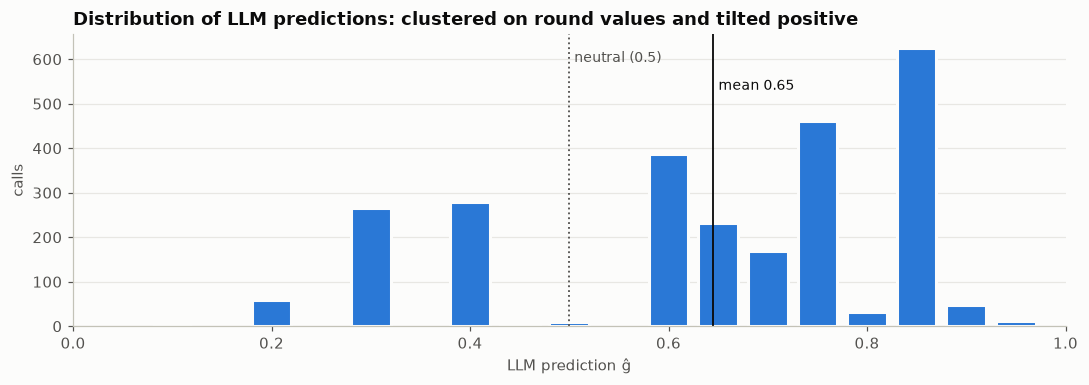

In [ ]:
ratio = s.sum_words_in / s.sum_words_out
desc = pd.DataFrame({
    'Transcript words': s.sum_words_in.describe(),
    'Summary words': s.sum_words_out.describe(),
    'Compression (x)': ratio.describe(),
    'Prediction ĝ': s.g.describe(),
}).T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(desc.round(2))
print(f'Summaries that needed the shortening pass: {(s.sum_passes > 1).sum()} of {N:,}')
print(f'Distinct prediction values: {s.g.nunique()} | share above 0.5: {(s.g > 0.5).mean():.1%} | '
      f'share below 0.5: {(s.g < 0.5).mean():.1%}')

counts = s.g.round(2).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(counts.index, counts.values, width=0.05, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(0.5, color=INK2, ls=':', lw=1.2)
ax.text(0.505, counts.max() * 0.95, 'neutral (0.5)', color=INK2, fontsize=9)
ax.axvline(s.g.mean(), color=INK, lw=1.2)
ax.text(s.g.mean() + 0.005, counts.max() * 0.85, f'mean {s.g.mean():.2f}', color=INK, fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel('LLM prediction ĝ')
ax.set_ylabel('calls')
ax.grid(axis='x', visible=False)
ax.set_title('Distribution of LLM predictions: clustered on round values and tilted positive')
fig.tight_layout()
plt.show()

In [ ]:
# One example: what the scorer saw (the summary) and what it returned
ex = s.sort_values('event_date').iloc[0]
print(f"{ex.ticker}  event {ex.event_date:%Y-%m-%d}  |  prediction {ex.g:.2f}  |  realized rank {ex.y:.2f}  "
      f"|  surprise rank {ex.s:.2f}\n")
print(ex.summary[:1500] + (' ...' if len(ex.summary) > 1500 else ''))
print('\nReasons:', '; '.join(json.loads(ex.reasons)))

AYI  event 2025-10-01  |  prediction 0.85  |  realized rank 0.75  |  surprise rank 0.45

RESULTS:  
- Q4 net sales: $1.2B, 17% above prior year.  
- Adjusted EPS: $5.20, up 21% YoY.  
- Adjusted operating margin: 18.6%, expanded 130 bps YoY.  

GUIDANCE:  
- FY26 net sales: $4.7B–$4.9B, RAISED vs. prior.  
- FY26 adjusted EPS: $19–$20.50, RAISED vs. prior.  
- Long-term: ABL to grow at low single-digit rate; AIS to grow organically in low to mid-teens.  

ONE-TIME ITEMS:  
- $31M noncash pension charge (U.S. & Mexico), depresses GAAP.  
- $8M one-time tax benefit, flatters adjusted results.  

MARGINS:  
- ABL margin: 20.1%, up 210 bps YoY, driven by cost actions.  
- AIS margin: 21.4%, improved on QSC integration and productivity.  
- Tariff cost + price increase impact: ~100 bps negative margin effect on ABL.  

TONE AND CAUTION:  
- “We’re demonstrating the ability to deliver in a tepid environment.”  
- “No modeling in expectations of improvement” for end markets.  

Q&A:  
- QSC m

## 3. Main regressions (the paper's Tables 2-3)

The specifications follow the paper's tables:
1. **(1) Baseline:** `y = a + θ·s`.
2. **(2) LLM alone:** `y = a + γ·ĝ`.
3. **(3) LLM + surprise:** `y = a + γ·ĝ + θ·s`.

Coefficients use conventional OLS standard errors in parentheses, as in the paper. R² comes with its 99% bootstrap
interval in brackets: resample calls with replacement, refit, and take the 0.5th and 99.5th percentiles.

Every specification uses the **same** bootstrap draws. That makes the interval for ΔR² = R²(3) − R²(1) a paired
one, which is the direct test of whether the LLM adds information beyond the surprise. Comparing two separate
intervals for overlap is a weaker test.

In [ ]:
IDX = np.random.default_rng(SEED).integers(0, N, size=(B, N))

def r2(y, X):
    X1 = np.column_stack([np.ones(len(y)), X])
    e = y - X1 @ np.linalg.lstsq(X1, y, rcond=None)[0]
    return 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))

def boot_r2(d, xs, idx=IDX):
    y, X = d['y'].to_numpy(float), d[xs].to_numpy(float)
    return np.array([r2(y[i], X[i]) for i in idx])

def ci(draws):
    return tuple(np.percentile(draws, [0.5, 99.5]))

LABELS = {'Intercept': 'Intercept', 'g': 'LLM prediction ĝ', 's': 'Surprise PRank(s)', 'g_rank': 'PRank(ĝ)'}

def reg_table(d, specs, idx=IDX):
    # Paper-style table: coef (SE), R² [99% CI], adj. R², N, F. Also returns the fits and bootstrap draws.
    cols, fits, draws = {}, {}, {}
    for name, xs in specs.items():
        res = smf.ols('y ~ ' + ' + '.join(xs), d).fit()
        dr = boot_r2(d, xs, idx)
        lo, hi = ci(dr)
        col = {LABELS[v]: (f'{res.params[v]:.3f} ({res.bse[v]:.3f})' if v in res.params else '')
               for v in ['Intercept'] + [v for v in LABELS if v != 'Intercept']}
        col.update({'R²': f'{res.rsquared:.3f} [{lo:.2f}, {hi:.2f}]', 'Adjusted R²': f'{res.rsquared_adj:.3f}',
                    'Observations': f'{int(res.nobs):,}', 'F statistic': f'{res.fvalue:.1f}'})
        cols[name], fits[name], draws[name] = col, res, dr
    t = pd.DataFrame(cols)
    return t.loc[(t != '').any(axis=1)], fits, draws

MAIN = {'(1) Baseline': ['s'], '(2) LLM': ['g'], '(3) LLM + surprise': ['g', 's']}
main_tab, FITS, DRAWS = reg_table(s, MAIN)
print(f'Dependent variable: PRank(r_abn) | LLM: {s.score_model.iloc[0]}, source = {s.score_source.iloc[0]}')
display(main_tab)

R2 = {k: FITS[k].rsquared for k in MAIN}
d_draws = DRAWS['(3) LLM + surprise'] - DRAWS['(1) Baseline']
D_R2, D_CI = R2['(3) LLM + surprise'] - R2['(1) Baseline'], ci(d_draws)
print(f'ΔR² (LLM on top of the surprise) = {D_R2:.3f}, paired 99% CI [{D_CI[0]:.3f}, {D_CI[1]:.3f}]; '
      f'excludes 0 in {(d_draws > 0).mean():.1%} of resamples')

Dependent variable: PRank(r_abn) | LLM: qwen3:30b-a3b-instruct-2507-q4_K_M, source = summary


,(1) Baseline,(2) LLM,(3) LLM + surprise
Intercept,0.391 (0.011),0.244 (0.019),0.185 (0.020)
LLM prediction ĝ,,0.397 (0.028),0.352 (0.028)
Surprise PRank(s),0.218 (0.019),,0.177 (0.019)
R²,"0.047 [0.02, 0.07]","0.072 [0.05, 0.10]","0.102 [0.07, 0.13]"
Adjusted R²,0.047,0.072,0.102
Observations,"2,584","2,584","2,584"
F statistic,128.5,200.2,147.0


ΔR² (LLM on top of the surprise) = 0.055, paired 99% CI [0.035, 0.081]; excludes 0 in 100.0% of resamples


## 4. Side by side with the paper

The paper's numbers were typed in from its Table 3 (summaries written by the same model that scores them, which
is our setup) and Table 2 (full transcripts), with N = 1,849. The paper reports intervals for each R², not for
ΔR², so its ΔR² is the difference of the two point estimates.

Differences to keep in mind:
- **Consensus:** the paper uses Benzinga, we use I/B/E/S.
- **Returns:** the paper uses Massive/Polygon, we use CRSP.
- **Sample:** we have 2,584 US calls, the paper has 1,849.
- **Model:** our model is an open-weights model run locally, and much smaller than Opus 4.5.

In [ ]:
PAPER_N = 1849
PAPER_BASE = {'r2': 0.050, 'ci': (0.03, 0.08), 'theta': 0.219}
#            label                                  LLM alone R², CI        LLM + s R², CI        γ (with s), θ (with s)
PAPER = {
    'GPT-5 nano (summaries)':            dict(llm=(0.030, (0.01, 0.05)), both=(0.073, (0.04, 0.11)), g=0.257, s=0.203),
    'Gemini 2.5 Flash-Lite (summaries)': dict(llm=(0.065, (0.04, 0.10)), both=(0.098, (0.07, 0.13)), g=0.252, s=0.180),
    'Opus 4.5 (summaries)':              dict(llm=(0.093, (0.06, 0.13)), both=(0.130, (0.09, 0.18)), g=0.442, s=0.189),
    'Opus 4.5 (full transcripts)':       dict(llm=(0.109, (0.08, 0.15)), both=(0.143, (0.10, 0.18)), g=0.565, s=0.181),
}
OURS = 'Qwen3-30B-A3B (summaries), ours'

def fmt(v, c, dp=2):
    return f'{v:.3f} [{c[0]:.{dp}f}, {c[1]:.{dp}f}]'

both = FITS['(3) LLM + surprise']
rows = {OURS: {
    'N': f'{N:,}',
    'Surprise only R²': fmt(R2['(1) Baseline'], ci(DRAWS['(1) Baseline'])),
    'LLM alone R²': fmt(R2['(2) LLM'], ci(DRAWS['(2) LLM'])),
    'LLM + surprise R²': fmt(R2['(3) LLM + surprise'], ci(DRAWS['(3) LLM + surprise'])),
    'ΔR² over surprise': fmt(D_R2, D_CI, 3),
    'γ on ĝ (with s)': f"{both.params['g']:.3f}",
    'θ on s (with ĝ)': f"{both.params['s']:.3f}",
    'θ drop vs. baseline': f"{FITS['(1) Baseline'].params['s']:.3f} → {both.params['s']:.3f}",
}}
for k, p in PAPER.items():
    rows[f'{k}, paper'] = {
        'N': f'{PAPER_N:,}',
        'Surprise only R²': fmt(PAPER_BASE['r2'], PAPER_BASE['ci']),
        'LLM alone R²': fmt(*p['llm']),
        'LLM + surprise R²': fmt(*p['both']),
        'ΔR² over surprise': f"{p['both'][0] - PAPER_BASE['r2']:.3f}",
        'γ on ĝ (with s)': f"{p['g']:.3f}",
        'θ on s (with ĝ)': f"{p['s']:.3f}",
        'θ drop vs. baseline': f"{PAPER_BASE['theta']:.3f} → {p['s']:.3f}",
    }
compare = pd.DataFrame(rows).T
display(compare)

,N,Surprise only R²,LLM alone R²,LLM + surprise R²,ΔR² over surprise,γ on ĝ (with s),θ on s (with ĝ),θ drop vs. baseline
"Qwen3-30B-A3B (summaries), ours","2,584","0.047 [0.02, 0.07]","0.072 [0.05, 0.10]","0.102 [0.07, 0.13]","0.055 [0.035, 0.081]",0.352,0.177,0.218 → 0.177
"GPT-5 nano (summaries), paper","1,849","0.050 [0.03, 0.08]","0.030 [0.01, 0.05]","0.073 [0.04, 0.11]",0.023,0.257,0.203,0.219 → 0.203
"Gemini 2.5 Flash-Lite (summaries), paper","1,849","0.050 [0.03, 0.08]","0.065 [0.04, 0.10]","0.098 [0.07, 0.13]",0.048,0.252,0.180,0.219 → 0.180
"Opus 4.5 (summaries), paper","1,849","0.050 [0.03, 0.08]","0.093 [0.06, 0.13]","0.130 [0.09, 0.18]",0.080,0.442,0.189,0.219 → 0.189
"Opus 4.5 (full transcripts), paper","1,849","0.050 [0.03, 0.08]","0.109 [0.08, 0.15]","0.143 [0.10, 0.18]",0.093,0.565,0.181,0.219 → 0.181


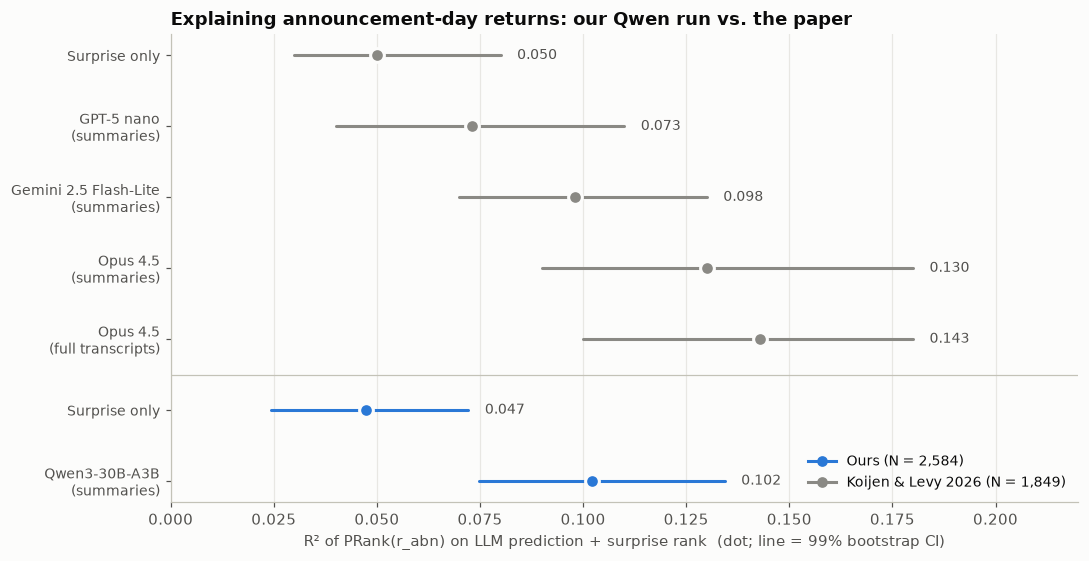

In [ ]:
# Dot-and-interval chart: R² of LLM + surprise (and the surprise-only baseline) for each system
items = [('Surprise only', PAPER_BASE['r2'], PAPER_BASE['ci'], 'paper')]
items += [(k.replace(' (', '\n('), p['both'][0], p['both'][1], 'paper') for k, p in PAPER.items()]
items += [('Surprise only', R2['(1) Baseline'], ci(DRAWS['(1) Baseline']), 'ours'),
          ('Qwen3-30B-A3B\n(summaries)', R2['(3) LLM + surprise'], ci(DRAWS['(3) LLM + surprise']), 'ours')]
items = items[::-1]   # first item on top

fig, ax = plt.subplots(figsize=(10, 5.2))
for i, (label, v, (lo, hi), who) in enumerate(items):
    c = BLUE if who == 'ours' else PAPER_GREY
    ax.plot([lo, hi], [i, i], color=c, lw=2, solid_capstyle='round')
    ax.plot(v, i, 'o', color=c, markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(hi + 0.004, i, f'{v:.3f}', va='center', fontsize=9, color=INK2)
ax.axhline(1.5, color='#c3c2b7', lw=0.8)
ax.set_yticks(range(len(items)), [it[0] for it in items], fontsize=9)
ax.set_xlim(0, 0.22)
ax.set_xlabel('R² of PRank(r_abn) on LLM prediction + surprise rank  (dot; line = 99% bootstrap CI)')
ax.grid(axis='y', visible=False)
ax.plot([], [], 'o-', color=BLUE, label=f'Ours (N = {N:,})')
ax.plot([], [], 'o-', color=PAPER_GREY, label=f'Koijen & Levy 2026 (N = {PAPER_N:,})')
ax.legend(loc='lower right', fontsize=9)
ax.set_title('Explaining announcement-day returns: our Qwen run vs. the paper')
fig.tight_layout()
plt.show()

## 5. Early vs. late announcements (the paper's Table 5)

The paper splits the quarter at the median event date. The early half is its training set for prompt
optimization, and the late half is held out. It finds the late half no harder, and if anything slightly easier.
Our split uses the same rule as `select_events`: early means `event_date <= median`.

In [ ]:
med = s.event_date.median()
halves = {'Early': s[s.event_date <= med], 'Late': s[s.event_date > med]}
PAPER_T5 = {'Gemini 2.5 Flash-Lite': {'Early': (0.093, (0.06, 0.14)), 'Late': (0.105, (0.06, 0.16))},
            'GPT-5 nano':            {'Early': (0.066, (0.04, 0.11)), 'Late': (0.085, (0.05, 0.14))},
            'Opus 4.5':              {'Early': (0.118, (0.07, 0.18)), 'Late': (0.141, (0.09, 0.20))}}
PAPER_T5_N = {'Early': 1032, 'Late': 817}

el, rng = {}, np.random.default_rng(SEED)
for h, d in halves.items():
    idx = rng.integers(0, len(d), size=(B, len(d)))
    tab, fits, dr = reg_table(d, {'base': ['s'], 'both': ['g', 's']}, idx)
    el[h] = {'N': len(d), 'base': (fits['base'].rsquared, ci(dr['base'])),
             'both': (fits['both'].rsquared, ci(dr['both'])),
             'gamma': fits['both'].params['g'], 'theta': fits['both'].params['s']}

t5 = pd.DataFrame({
    **{f'Ours: {h}': {'N': f"{v['N']:,}", 'Surprise only R²': fmt(*v['base']), 'LLM + surprise R²': fmt(*v['both']),
                      'γ': f"{v['gamma']:.3f}", 'θ': f"{v['theta']:.3f}"} for h, v in el.items()},
    **{f'{m} (paper): {h}': {'N': f'{PAPER_T5_N[h]:,}', 'Surprise only R²': '', 'LLM + surprise R²': fmt(*p[h]),
                             'γ': '', 'θ': ''} for m, p in PAPER_T5.items() for h in ('Early', 'Late')},
}).T
print(f'Median event date: {med:%Y-%m-%d}')
display(t5)

Median event date: 2025-11-05


,N,Surprise only R²,LLM + surprise R²,γ,θ
Ours: Early,"1,443","0.059 [0.03, 0.10]","0.109 [0.07, 0.15]",0.330,0.211
Ours: Late,"1,141","0.039 [0.01, 0.08]","0.096 [0.06, 0.15]",0.370,0.151
Gemini 2.5 Flash-Lite (paper): Early,"1,032",,"0.093 [0.06, 0.14]",,
Gemini 2.5 Flash-Lite (paper): Late,817,,"0.105 [0.06, 0.16]",,
GPT-5 nano (paper): Early,"1,032",,"0.066 [0.04, 0.11]",,
GPT-5 nano (paper): Late,817,,"0.085 [0.05, 0.14]",,
Opus 4.5 (paper): Early,"1,032",,"0.118 [0.07, 0.18]",,
Opus 4.5 (paper): Late,817,,"0.141 [0.09, 0.20]",,


## 6. Calibration: does the model think every call is good news?

Events are sorted into quintiles of each signal. For each quintile the chart plots the **average signal** on the
x-axis against the **average realized return rank** on the y-axis. On the dotted diagonal the signal would be a
calibrated rank. A curve that slopes up but sits right of the diagonal means the model ranks well but is biased
toward optimism. That is the paper's "good is priced in" finding, which its GEPA prompt optimization learned to
correct.

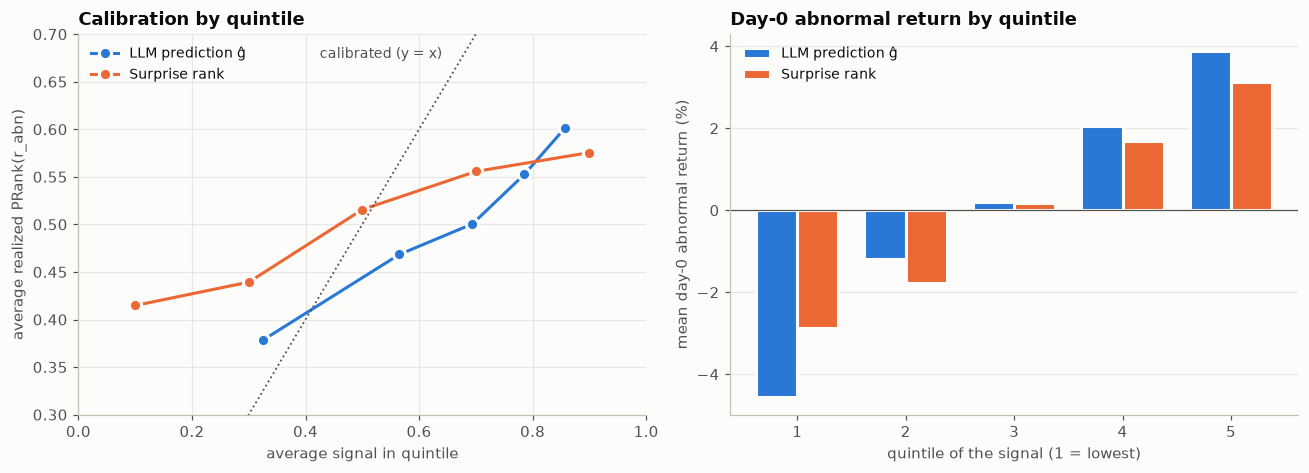

LLM prediction  Q5 - Q1 day-0 abnormal return:  8.44%  (t = 11.9)
Surprise        Q5 - Q1 day-0 abnormal return:  6.01%  (t = 7.7)
Mean prediction 0.645 vs. mean realized rank 0.500: bias of +0.145


In [ ]:
def quintile(x):
    return pd.qcut(x.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

s['q_g'], s['q_s'] = quintile(s.g), quintile(s.s)
cal = {name: s.groupby(col).agg(signal=(sig, 'mean'), realized=('y', 'mean'), r_abn=('r_abn', 'mean'), n=('y', 'size'))
       for name, col, sig in [('LLM prediction ĝ', 'q_g', 'g'), ('Surprise rank', 'q_s', 's')]}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for (name, c), color in zip(cal.items(), [BLUE, ORANGE]):
    a1.plot(c.signal, c.realized, '-o', color=color, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
            label=name)
a1.plot([0, 1], [0, 1], ':', color=INK2, lw=1.2)
a1.text(0.64, 0.675, 'calibrated (y = x)', color=INK2, fontsize=9, ha='right')
a1.set(xlim=(0, 1), ylim=(0.3, 0.7), xlabel='average signal in quintile', ylabel='average realized PRank(r_abn)')
a1.legend(loc='upper left', fontsize=9)
a1.set_title('Calibration by quintile')

x = np.arange(1, 6)
w = 0.38
for k, ((name, c), color) in enumerate(zip(cal.items(), [BLUE, ORANGE])):
    a2.bar(x + (k - 0.5) * w, c.r_abn * 100, width=w, color=color, edgecolor=SURFACE, linewidth=2, label=name)
a2.axhline(0, color=INK2, lw=0.8)
a2.set(xticks=x, xlabel='quintile of the signal (1 = lowest)', ylabel='mean day-0 abnormal return (%)')
a2.grid(axis='x', visible=False)
a2.legend(loc='upper left', fontsize=9)
a2.set_title('Day-0 abnormal return by quintile')
fig.tight_layout()
plt.show()

def spread(col):
    top, bot = s.loc[s[col] == 5, 'r_abn'], s.loc[s[col] == 1, 'r_abn']
    d = top.mean() - bot.mean()
    return d, d / np.sqrt(top.var() / len(top) + bot.var() / len(bot))
for name, col in [('LLM prediction', 'q_g'), ('Surprise', 'q_s')]:
    d, t = spread(col)
    print(f'{name:15s} Q5 - Q1 day-0 abnormal return: {d * 100:5.2f}%  (t = {t:.1f})')
print(f'Mean prediction {s.g.mean():.3f} vs. mean realized rank {s.y.mean():.3f}: '
      f'bias of {s.g.mean() - s.y.mean():+.3f}')

## 7. Robustness

- **Ranked prediction:** `PRank(ĝ)` replaces `ĝ`. This takes out the model's own scale and its bias.
- **Clustered standard errors:** calls on the same event date share market and industry shocks, so the t-stats
  are recomputed with standard errors clustered by event date.
- **Summary length:** the result is rerun without the summaries that needed the shortening pass.

In [ ]:
rob = {}
for name, d, xs in [('Main: ĝ + s', s, ['g', 's']),
                    ('PRank(ĝ) + s', s, ['g_rank', 's']),
                    ('ĝ + s, one-pass summaries only', s[s.sum_passes == 1], ['g', 's'])]:
    res = smf.ols('y ~ ' + ' + '.join(xs), d).fit()
    cl = smf.ols('y ~ ' + ' + '.join(xs), d).fit(cov_type='cluster', cov_kwds={'groups': d['date']})
    base = smf.ols('y ~ s', d).fit().rsquared
    rob[name] = {'N': f'{int(res.nobs):,}', 'R²': f'{res.rsquared:.3f}', 'ΔR² over s': f'{res.rsquared - base:.3f}',
                 'LLM coef': f'{res.params[xs[0]]:.3f}', 't (OLS)': f'{res.tvalues[xs[0]]:.1f}',
                 't (clustered by date)': f'{cl.tvalues[xs[0]]:.1f}', 's coef': f"{res.params['s']:.3f}",
                 's t (clustered)': f"{cl.tvalues['s']:.1f}"}
display(pd.DataFrame(rob).T)
print(f"{s.date.nunique()} event-date clusters")

,N,R²,ΔR² over s,LLM coef,t (OLS),t (clustered by date),s coef,s t (clustered)
Main: ĝ + s,"2,584",0.102,0.055,0.352,12.6,14.8,0.177,10.2
PRank(ĝ) + s,"2,584",0.102,0.055,0.240,12.5,13.8,0.182,10.5
"ĝ + s, one-pass summaries only","2,529",0.100,0.053,0.346,12.2,14.7,0.177,9.7


53 event-date clusters


## 8. Takeaways

Numbers are from the run on 2,584 Q4 2025 US calls. They are written out by hand, so rerunning on new data
updates the tables above but not this text.

- **The baseline replicates.** The surprise alone explains R² = 0.047 [0.02, 0.07] of the return rank, against
  the paper's 0.050, with almost the same slope (0.218 vs. 0.219).
- **The LLM adds information the surprise misses.**
  - Qwen alone explains 0.072. Together with the surprise it explains **0.102 [0.07, 0.13]**, roughly double the
    baseline.
  - The paired gain is **ΔR² = 0.055, 99% CI [0.035, 0.081]**, so the increment is clearly not zero.
  - The surprise coefficient barely drops (0.218 → 0.177), the same pattern as in the paper (0.219 → 0.18-0.20).
    The two signals are complements: the LLM picks up guidance, margins and tone, not the earnings beat itself.
- **Against the paper, Qwen3-30B sits between Gemini 2.5 Flash-Lite and Opus 4.5** on summaries:
  - LLM + surprise: 0.102 for us, vs. 0.098 for Gemini, 0.130 for Opus and 0.073 for GPT-5 nano.
  - ΔR²: 0.055 for us, vs. 0.048 for Gemini and 0.080 for Opus.
  - Our interval overlaps Opus's [0.09, 0.18], so the gap to Opus is not significant at 1%. This is a small,
    open-weights model run locally.
- **The result holds in the late half.**
  - LLM + surprise: 0.109 early vs. 0.096 late. The paper's numbers rise slightly instead, but the two intervals
    overlap heavily.
  - The surprise also explains less in the late half (0.059 → 0.039), so the LLM's increment is about the same
    in both halves (0.050 early, 0.057 late).
- **The model ranks well but is optimistic.**
  - Mean prediction is 0.645 against a mean realized rank of 0.50. 76% of predictions are above 0.5, and almost
    none are exactly 0.5.
  - This is the paper's "good is priced in" bias.
  - Using `PRank(ĝ)` instead of `ĝ` gives the same R² (0.102), so the bias costs nothing here. That matches the
    paper's point that de-biasing (what GEPA mostly learned) adds little R². Gains have to come from better
    *ranking*.
- **The day-0 spread is large.** Top minus bottom quintile of ĝ is 8.4% (t = 11.9), against 6.0% for the surprise.
  This is the announcement reaction itself, so it is not tradable.
- **The results are robust.** t-stats clustered by event date are 14.8 for ĝ and 10.2 for s. Dropping the 55
  summaries that needed a second shortening pass leaves R² at 0.100.

**Caveats:**
- Different data sources: I/B/E/S and CRSP here, Benzinga and Massive in the paper.
- More calls: 2,584 here, 1,849 in the paper.
- ĝ takes only 14 distinct values, so its quintiles split ties by row order.
- Until `uv run doit` is rerun locally, the surprise and return columns come from the copy saved in the LLM file.
  It agrees with the local pipeline file except for 2 calls.

**Next steps:**
1. **Post-announcement drift:** run `signals/long_short.py` with ĝ as the signal for 1-, 4- and 12-week CARs. This
   is the stage-gate question, and the only tradable one.
2. **By industry (FF12):** reuse the SIC cache from `table1.ipynb`.
3. **Full transcripts:** score them for the paper's Table 2 comparison (Opus gained about 1.3pp from full text).
4. **Prompt optimization:** try GEPA or ACE on the early half and evaluate on the late half, aiming at ranking
   rather than bias.